# Choosing the threshold

I use out-of-fold training scores so the test files stay untouched.

In [1]:
from pathlib import Path
import json
import os
import sys

# The stored OOF scores follow the cleaned training-row order.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from data import clean_train, load
from metrics import deployed_precision, threshold_for_fpr

oof = pd.read_csv(ROOT / "reports/oof_scores.csv")
train_clean, _ = clean_train(load("train"))
y = train_clean.label.to_numpy()
scores = oof.advanced.to_numpy()
train_summary = json.loads((ROOT / "reports/train_summary.json").read_text())
chosen = train_summary["advanced"]["threshold"]
reproduced = threshold_for_fpr(y, scores, 0.01)
assert round(reproduced, 4) == chosen
print({"reproduced_threshold": reproduced, "stored_threshold": chosen})

{'reproduced_threshold': 0.9708510000000001, 'stored_threshold': 0.9709}


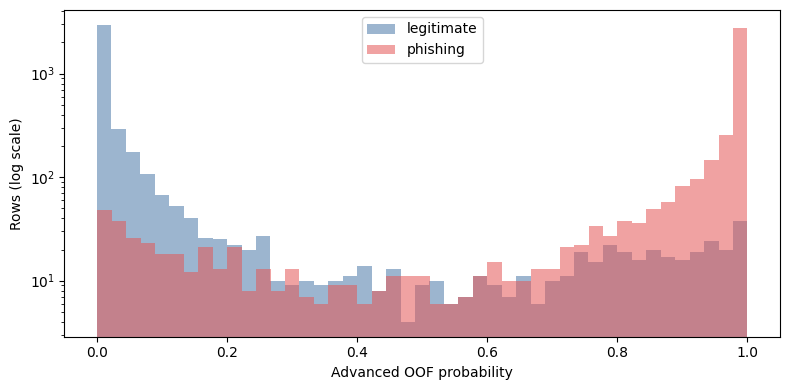

In [2]:
# Log counts make the small high-score tail readable.
fig, ax = plt.subplots(figsize=(8, 4))
for label, color, name in ((0, "#4c78a8", "legitimate"),
                           (1, "#e45756", "phishing")):
    ax.hist(scores[y == label], bins=45, alpha=0.55, color=color, label=name)
ax.set_yscale("log")
ax.set(xlabel="Advanced OOF probability", ylabel="Rows (log scale)")
ax.legend()
fig.tight_layout()
plt.show()
plt.close(fig)

I look at the overlap in the tails because the operating point is set by the legitimate URLs that score highest.

{'legitimate_oof_rows': 4257, 'index_after_allowed_false_positives': 42, 'next_score_cutoff': 0.970851, 'threshold_just_above_cutoff': 0.9708510000000001}


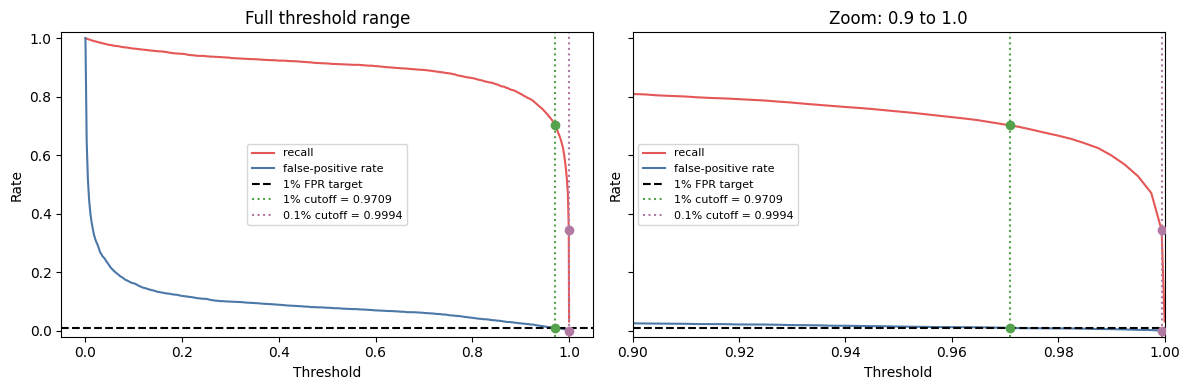

In [3]:
# Sort only the legitimate OOF scores to see the 1% false-positive cutoff.
legit_scores = np.sort(scores[y == 0])[::-1]
allowed_false_positives = int(0.01 * len(legit_scores))
cutoff_score = legit_scores[allowed_false_positives]
print({"legitimate_oof_rows": len(legit_scores),
       "index_after_allowed_false_positives": allowed_false_positives,
       "next_score_cutoff": cutoff_score,
       "threshold_just_above_cutoff": reproduced})

# Keep both operating points in the grid and zoom in on the high-score tail.
tight = threshold_for_fpr(y, scores, 0.001)
thresholds = np.unique(np.r_[np.linspace(scores.min(), scores.max(), 400), chosen, tight])
recall = np.array([(scores[y == 1] >= t).mean() for t in thresholds])
fpr = np.array([(scores[y == 0] >= t).mean() for t in thresholds])
chosen_idx = int(np.searchsorted(thresholds, chosen))
tight_idx = int(np.searchsorted(thresholds, tight))
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for axis in axes:
    axis.plot(thresholds, recall, label="recall", color="#e45756")
    axis.plot(thresholds, fpr, label="false-positive rate", color="#4c78a8")
    axis.axhline(0.01, color="black", linestyle="--", label="1% FPR target")
    axis.axvline(chosen, color="#54a24b", linestyle=":", label=f"1% cutoff = {chosen:.4f}")
    axis.axvline(tight, color="#b279a2", linestyle=":", label=f"0.1% cutoff = {tight:.4f}")
    axis.scatter([chosen, chosen], [recall[chosen_idx], fpr[chosen_idx]],
                 color="#54a24b", zorder=3)
    axis.scatter([tight, tight], [recall[tight_idx], fpr[tight_idx]],
                 color="#b279a2", zorder=3)
    axis.set(xlabel="Threshold", ylabel="Rate", ylim=(-0.02, 1.02))
    axis.legend(fontsize=8)
axes[0].set_title("Full threshold range")
axes[1].set(xlim=(0.9, 1.0), title="Zoom: 0.9 to 1.0")
fig.tight_layout()
plt.show()
plt.close(fig)

I sort the legitimate scores and choose just above the 1% cutoff; the second panel zooms in where the high-score thresholds sit. The 0.1% point needs a much higher cutoff.

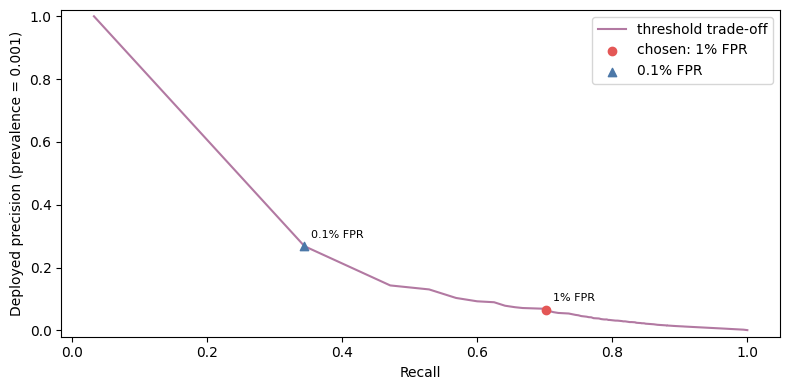

,target_fpr,threshold,val_recall,val_fpr,val_false_positives,deployed_precision
0,0.050,0.7760,0.8712,0.04980,212,0.0172
1,0.020,0.9296,0.7804,0.01997,85,0.0377
2,0.010,0.9709,0.7021,0.00987,42,0.0665
3,0.005,0.9915,0.5825,0.00493,21,0.1057
4,0.001,0.9994,0.3439,0.00094,4,0.2681


In [4]:
# Deployment precision uses one phishing URL per thousand as the assumed prevalence.
precision = deployed_precision(recall, fpr)
finite = np.isfinite(precision)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(recall[finite], precision[finite], color="#b279a2", label="threshold trade-off")
ax.scatter([recall[chosen_idx]], [precision[chosen_idx]], color="#e45756",
           label="chosen: 1% FPR", zorder=3)
ax.scatter([recall[tight_idx]], [precision[tight_idx]], color="#4c78a8",
           marker="^", label="0.1% FPR", zorder=3)
ax.annotate("1% FPR", (recall[chosen_idx], precision[chosen_idx]),
            xytext=(5, 6), textcoords="offset points", fontsize=8)
ax.annotate("0.1% FPR", (recall[tight_idx], precision[tight_idx]),
            xytext=(5, 6), textcoords="offset points", fontsize=8)
ax.set(xlabel="Recall", ylabel="Deployed precision (prevalence = 0.001)",
       ylim=(-0.02, 1.02))
ax.legend()
fig.tight_layout()
plt.show()
plt.close(fig)
display(pd.DataFrame(train_summary["advanced"]["validation_thresholds"]))

At the chosen 1% point, validation recall is 0.702 and implied precision is 0.067; the 0.1% point trades recall down to 0.344 for precision 0.268, based on just four false positives. This is a review queue, not an automatic block, and OOF keeps the test files untouched.